# 08 - Comparación de modelos

Este notebook junta los resultados de todos los modelos y genera las gráficas estáticas del informe.
Lee cualquier archivo `results/metrics_*.csv` y `results/predictions_*.csv` que exista, así que si se
agrega un modelo nuevo (por ejemplo el de la CNN) basta con volver a correr todo el notebook.

## 1. Carga de resultados

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

RESULTS_DIR = Path("../results")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

CLASSES = ["bg", "play", "challenge", "throwin"]
MODEL_NAMES = {
    "dummy": "Dummy",
    "logreg": "Regresión Logística",
    "rf": "Random Forest",
    "hgb": "HistGradientBoosting",
    "cnn": "ResNet18 + clasificador",
}
# Mismos colores que usa la app, para que el informe y la app se vean como un solo trabajo.
MODEL_COLORS = {
    "dummy": "#8a8984",
    "logreg": "#2a78d6",
    "rf": "#eb6834",
    "hgb": "#1baf7a",
    "cnn": "#6250d6",
}

sns.set_theme(style="whitegrid", font_scale=1.0)

metrics = pd.concat([pd.read_csv(f) for f in sorted(RESULTS_DIR.glob("metrics_*.csv"))], ignore_index=True)
preds = pd.concat([pd.read_csv(f) for f in sorted(RESULTS_DIR.glob("predictions_*.csv"))], ignore_index=True)

# Orden fijo: el Dummy primero como referencia, el resto como aparezcan.
models = [m for m in MODEL_NAMES if m in metrics["model"].unique()]
models += [m for m in metrics["model"].unique() if m not in models]
for m in models:
    MODEL_NAMES.setdefault(m, m)
    MODEL_COLORS.setdefault(m, "#444444")

print("Modelos encontrados:", [MODEL_NAMES[m] for m in models])
print("Videos usados como prueba:", sorted(metrics["fold"].unique()))


Modelos encontrados: ['Dummy', 'Regresión Logística', 'Random Forest', 'HistGradientBoosting']
Videos usados como prueba: ['1606b0e6_0', '1606b0e6_1', '35bd9041_0']


## 2. Tabla resumen

Promedio y desviación estándar sobre los videos de prueba. Con solo 3 videos la desviación es
grande, así que las diferencias pequeñas entre modelos no son concluyentes.

In [2]:
cols = ["accuracy", "f1_macro", "f1_bg", "f1_play", "f1_challenge", "f1_throwin", "train_time_s", "pred_time_ms"]
resumen = metrics.groupby("model")[cols].agg(["mean", "std"]).loc[models]
tabla = pd.DataFrame({
    "Modelo": [MODEL_NAMES[m] for m in models],
    "Accuracy": [f"{resumen.loc[m, ('accuracy','mean')]:.3f} ± {resumen.loc[m, ('accuracy','std')]:.3f}" for m in models],
    "F1 macro": [f"{resumen.loc[m, ('f1_macro','mean')]:.3f} ± {resumen.loc[m, ('f1_macro','std')]:.3f}" for m in models],
    "Tiempo de entrenamiento (s)": [f"{resumen.loc[m, ('train_time_s','mean')]:.2f}" for m in models],
    "Tiempo de predicción (ms por frame)": [f"{resumen.loc[m, ('pred_time_ms','mean')]:.4f}" for m in models],
})
tabla


,Modelo,Accuracy,F1 macro,Tiempo de entrenamiento (s),Tiempo de predicción (ms por frame)
0,Dummy,0.780 ± 0.040,0.219 ± 0.006,0.00,0.0000
1,Regresión Logística,0.719 ± 0.090,0.221 ± 0.008,0.53,0.0003
2,Random Forest,0.735 ± 0.076,0.240 ± 0.035,10.44,0.0143
3,HistGradientBoosting,0.620 ± 0.189,0.224 ± 0.002,38.18,0.0146


## 3. F1 por clase y modelo

El accuracy engaña cuando una clase domina, por eso se compara el F1 de cada clase por separado.
Las barras son el promedio de los videos de prueba y las líneas negras la desviación estándar.

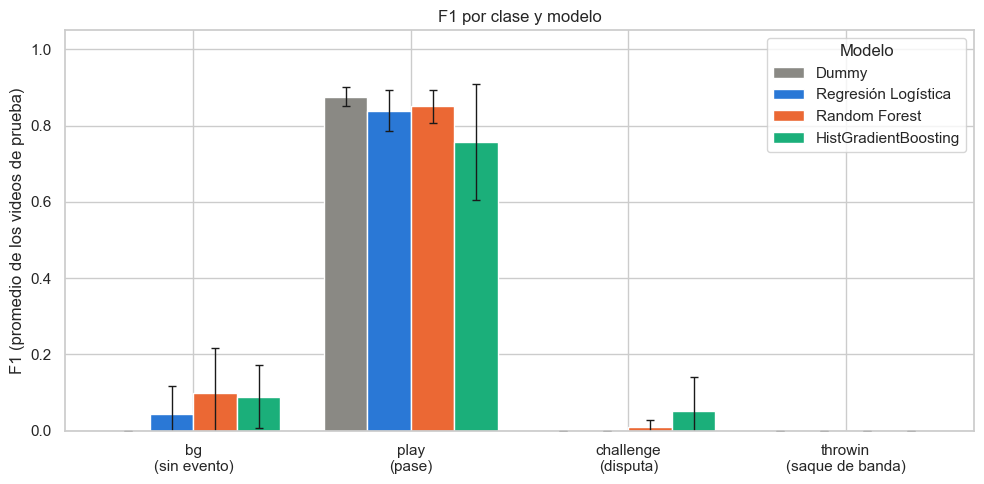

In [3]:
f1_cols = {"bg": "f1_bg", "play": "f1_play", "challenge": "f1_challenge", "throwin": "f1_throwin"}
CLASS_LABELS = {"bg": "bg\n(sin evento)", "play": "play\n(pase)", "challenge": "challenge\n(disputa)", "throwin": "throwin\n(saque de banda)"}

fig, ax = plt.subplots(figsize=(10, 5))
width = 0.8 / len(models)
x = np.arange(len(CLASSES))
for i, m in enumerate(models):
    sub = metrics[metrics["model"] == m]
    means = [sub[f1_cols[c]].mean() for c in CLASSES]
    stds = [sub[f1_cols[c]].std() for c in CLASSES]
    ax.bar(x + (i - (len(models) - 1) / 2) * width, means, width, yerr=stds, capsize=3,
           color=MODEL_COLORS[m], label=MODEL_NAMES[m], edgecolor="white", error_kw={"elinewidth": 1})
ax.set_xticks(x)
ax.set_xticklabels([CLASS_LABELS[c] for c in CLASSES])
ax.set_ylabel("F1 (promedio de los videos de prueba)")
ax.set_ylim(0, 1.05)
ax.set_title("F1 por clase y modelo")
ax.legend(title="Modelo", loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "12_f1_por_clase_y_modelo.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Matrices de confusión

Se juntan las predicciones de todos los videos de prueba. Cada fila suma 100%, así que se lee como
"de los frames que de verdad eran de esta clase, qué porcentaje se predijo como cada una". Debajo
del porcentaje va la cantidad de frames.

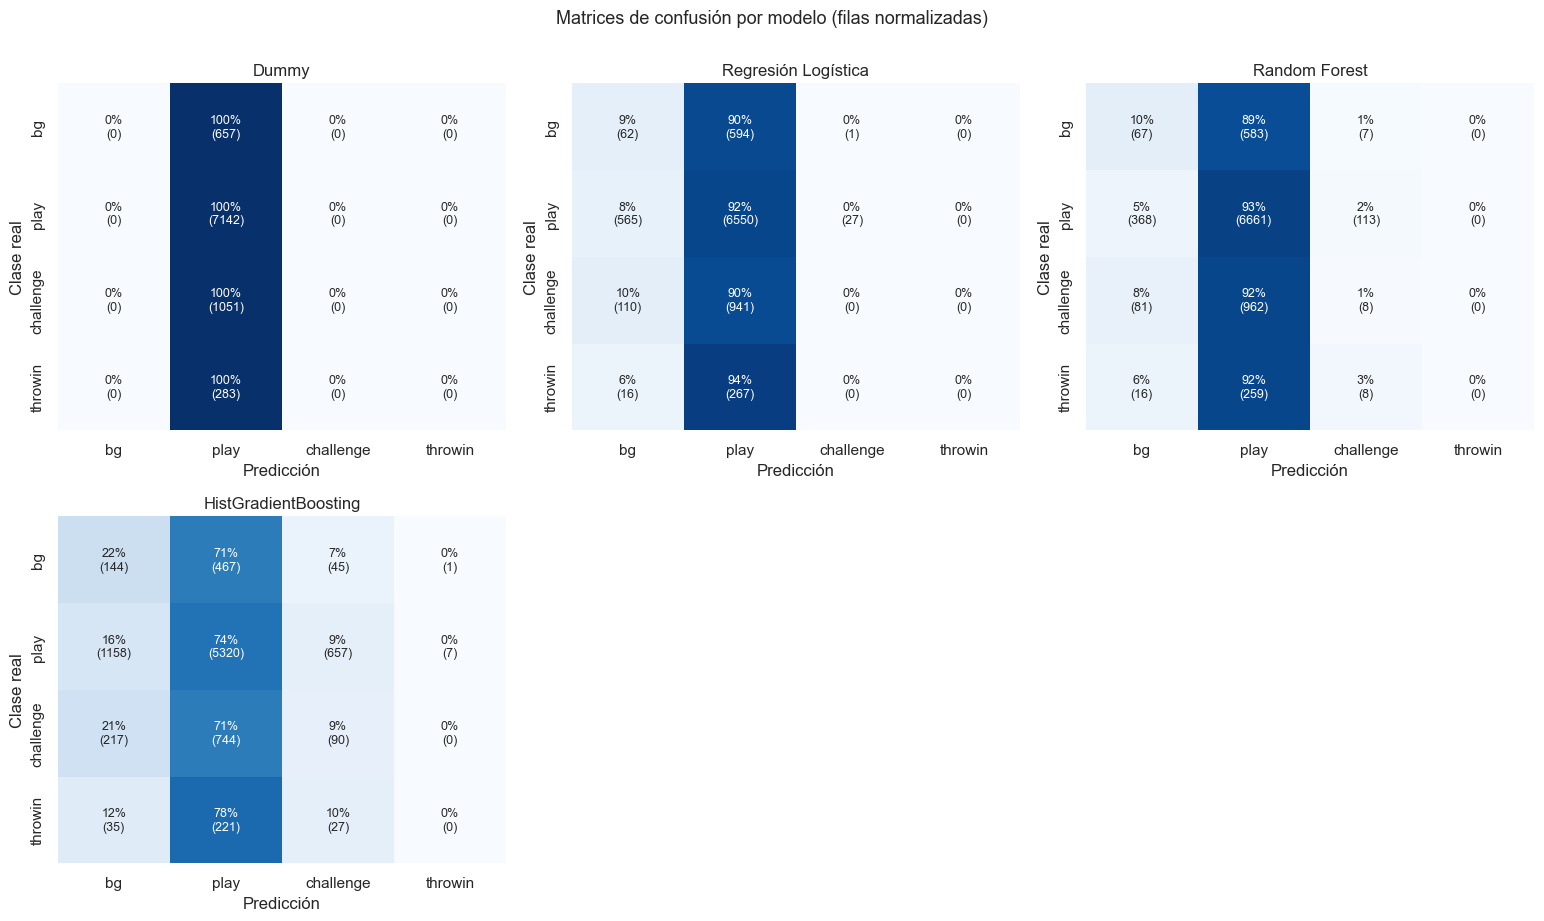

In [4]:
n = len(models)
ncols = min(n, 3)
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.6 * nrows), squeeze=False)

for ax, m in zip(axes.ravel(), models):
    sub = preds[preds["model"] == m]
    cm = confusion_matrix(sub["label"], sub["pred"], labels=CLASSES)
    pct = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    annot = np.array([[f"{pct[i, j]:.0%}\n({cm[i, j]})" for j in range(len(CLASSES))] for i in range(len(CLASSES))])
    sns.heatmap(pct, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, annot_kws={"fontsize": 9})
    ax.set_title(MODEL_NAMES[m])
    ax.set_xlabel("Predicción")
    ax.set_ylabel("Clase real")
for ax in axes.ravel()[n:]:
    ax.axis("off")

fig.suptitle("Matrices de confusión por modelo (filas normalizadas)", y=1.0, fontsize=13)
plt.tight_layout()
plt.savefig(FIG_DIR / "13_matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Tiempo vs. desempeño

Cada punto es un modelo. El eje horizontal es el tiempo de entrenamiento (escala logarítmica, porque
varía en varios órdenes de magnitud) y el vertical el F1 macro. Interesa estar arriba y a la
izquierda.

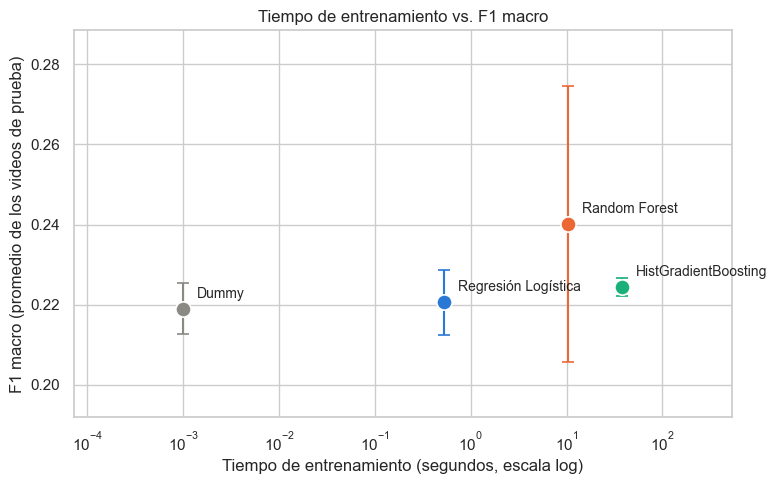

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for m in models:
    sub = metrics[metrics["model"] == m]
    xm, ym = sub["train_time_s"].mean(), sub["f1_macro"].mean()
    ax.errorbar(xm, ym, yerr=sub["f1_macro"].std(), fmt="o", markersize=11, color=MODEL_COLORS[m],
                ecolor=MODEL_COLORS[m], capsize=4, markeredgecolor="white", markeredgewidth=1.2)
    ax.annotate(MODEL_NAMES[m], (xm, ym), textcoords="offset points", xytext=(10, 8), fontsize=10)
ax.set_xscale("log")
ax.set_xlabel("Tiempo de entrenamiento (segundos, escala log)")
ax.set_ylabel("F1 macro (promedio de los videos de prueba)")
ax.set_title("Tiempo de entrenamiento vs. F1 macro")
ax.margins(x=0.25, y=0.2)
plt.tight_layout()
plt.savefig(FIG_DIR / "14_tiempo_vs_desempeno.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. F1 macro por video de prueba

Muestra qué tanto cambia el resultado de un video a otro. Si un modelo gana en un video y pierde en
otro, la ventaja promedio no es confiable.

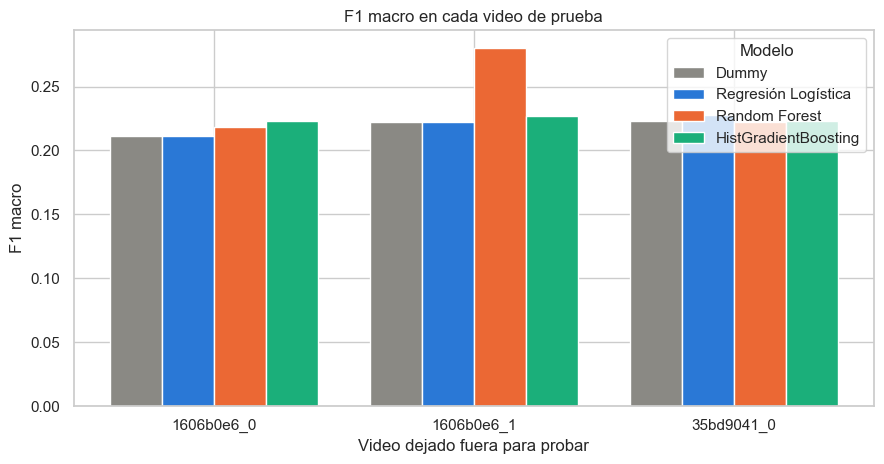

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.8))
folds = sorted(metrics["fold"].unique())
width = 0.8 / len(models)
x = np.arange(len(folds))
for i, m in enumerate(models):
    sub = metrics[metrics["model"] == m].set_index("fold").loc[folds]
    ax.bar(x + (i - (len(models) - 1) / 2) * width, sub["f1_macro"], width,
           color=MODEL_COLORS[m], label=MODEL_NAMES[m], edgecolor="white")
ax.set_xticks(x)
ax.set_xticklabels(folds)
ax.set_xlabel("Video dejado fuera para probar")
ax.set_ylabel("F1 macro")
ax.set_title("F1 macro en cada video de prueba")
ax.legend(title="Modelo")
plt.tight_layout()
plt.savefig(FIG_DIR / "15_f1_macro_por_video.png", dpi=150, bbox_inches="tight")
plt.show()


## 7. Lectura automática de los resultados

In [7]:
prom = metrics.groupby("model")[cols].mean().loc[models]
mejor = prom["f1_macro"].idxmax()
dummy_f1 = prom.loc["dummy", "f1_macro"] if "dummy" in prom.index else float("nan")

print(f"Mejor F1 macro: {MODEL_NAMES[mejor]} ({prom.loc[mejor, 'f1_macro']:.3f}). El Dummy tiene {dummy_f1:.3f}.")
print(f"Más rápido de entrenar: {MODEL_NAMES[prom['train_time_s'].idxmin()]} ({prom['train_time_s'].min():.3f} s).")
print(f"Más lento de entrenar: {MODEL_NAMES[prom['train_time_s'].idxmax()]} ({prom['train_time_s'].max():.1f} s).")
print()
for c in ["f1_challenge", "f1_throwin"]:
    mejor_c = prom[c].idxmax()
    print(f"{c}: el mejor es {MODEL_NAMES[mejor_c]} con {prom.loc[mejor_c, c]:.3f}.")
sin_throwin = [MODEL_NAMES[m] for m in models if prom.loc[m, "f1_throwin"] == 0]
print("Modelos que nunca detectan throwin:", ", ".join(sin_throwin) if sin_throwin else "ninguno")


Mejor F1 macro: Random Forest (0.240). El Dummy tiene 0.219.
Más rápido de entrenar: Dummy (0.001 s).
Más lento de entrenar: HistGradientBoosting (38.2 s).

f1_challenge: el mejor es HistGradientBoosting con 0.051.
f1_throwin: el mejor es Dummy con 0.000.
Modelos que nunca detectan throwin: Dummy, Regresión Logística, Random Forest, HistGradientBoosting
